# Guia dos dados: ações e puts do setor elétrico (COTAHIST/B3)

Notebook de **consulta**. Serve para responder rápido a perguntas do tipo *"o que é essa coluna?"*, *"quais ações têm puts?"*, *"quantas séries existem em 2023?"* ou *"o preço está ajustado?"*.

| Seção | Conteúdo |
|---|---|
| 1 | Os arquivos e de onde vêm |
| 2 | **Dicionário de colunas** (todas, com unidade e exemplo) |
| 3 | Códigos da B3: `tpmerc`, `codbdi`, `especi` e o código de negociação das opções |
| 4 | Ações: cobertura, estatísticas e gráficos |
| 5 | Puts: cobertura, estatísticas e gráficos |
| 6 | Checagens de qualidade dos dados |
| 7 | Funções de consulta rápida |

**Aviso importante:** os preços são **brutos**, exatamente como negociados no pregão. Eles **não** são ajustados por desdobramentos, bonificações ou dividendos (ver Seção 4.3). Para análises de retorno e risco, use o ajuste feito em `monte_carlo_risco_hedging_b3.ipynb`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
DADOS = RAIZ / "data_store" / "cotahist"

plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.alpha": 0.25, "legend.frameon": False,
})
AZUL, LARANJA, VERDE, VERMELHO, CINZA = "#1f4e79", "#c55a11", "#2e7d32", "#b71c1c", "#7f7f7f"
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 200
pd.options.display.max_columns = 30

---
## 1. Os arquivos

A B3 publica um arquivo por ano, `COTAHIST_A<ano>.ZIP`: um texto de largura fixa com **uma linha por instrumento por pregão**. Ele é gratuito e público e inclui as séries de opções já vencidas. O script `scripts/collect_cotahist.py` (lógica em `src/finstrategy/data/cotahist_provider.py`) baixou os anos de 2010 a 2026, filtrou as **raízes do setor elétrico** (TAEE, CMIG, EGIE, CPFE, CPLE, ELET, EQTL, ENEV, ENGI…) e gravou três CSVs:

| Arquivo | Conteúdo |
|---|---|
| `eletrico_acao_2010_2026.csv` | só ações à vista (`tpmerc = 10`) |
| `eletrico_put_2010_2026.csv` | só opções de venda (`tpmerc = 80`) |
| `eletrico_2010_2026.csv` | os dois juntos (mesmas linhas, empilhadas) |

Os `.ZIP` originais também estão na pasta e podem ser relidos com o `CotahistProvider`. Não há opções de compra (calls) nestes CSVs: elas não foram extraídas.

In [2]:
for f in sorted(DADOS.glob("*.csv")):
    print(f"{f.name:35s} {f.stat().st_size / 1e6:7.1f} MB")

acoes = pd.read_csv(DADOS / "eletrico_acao_2010_2026.csv", parse_dates=["data_pregao", "datven"])
puts = pd.read_csv(DADOS / "eletrico_put_2010_2026.csv", parse_dates=["data_pregao", "datven"])
todos = pd.read_csv(DADOS / "eletrico_2010_2026.csv", usecols=["classe"])
print(f"\nações: {len(acoes):,} linhas | puts: {len(puts):,} linhas | arquivo conjunto: {len(todos):,} linhas "
      f"(= soma? {len(todos) == len(acoes) + len(puts)})".replace(",", "."))
print(f"período: {acoes.data_pregao.min().date()} a {acoes.data_pregao.max().date()}")
display(puts.head(3))

eletrico_2010_2026.csv                 53.9 MB
eletrico_acao_2010_2026.csv            11.9 MB
eletrico_put_2010_2026.csv             42.0 MB



ações: 96.841 linhas | puts: 362.553 linhas | arquivo conjunto: 459.394 linhas (= soma? True)
período: 2010-01-04 a 2026-10-16


,data_pregao,codbdi,codneg,tpmerc,nomres,especi,preabe,premax,premin,premed,preult,totneg,quatot,voltot,preexe,datven,codisi,classe
0,2016-07-29,82,ALUPM15,80,ALUPE,UNT N2,0.60,0.60,0.40,0.55,0.40,3,200000,"111,400.00",15.00,2017-01-16,BRALUPCDAM15,put
1,2022-12-15,82,ALUPM180,80,ALUPE,UNT N2,0.01,0.01,0.01,0.01,0.01,1,100,1.00,18.00,2023-01-20,BRALUPCDAM15,put
2,2022-12-09,82,ALUPM200,80,ALUPE,UNT N2,0.01,0.01,0.01,0.01,0.01,1,100,1.00,20.00,2023-01-20,BRALUPCDAM15,put


---
## 2. Dicionário de colunas

Todas as 18 colunas são as mesmas nos três arquivos. Na COTAHIST, os preços têm 2 casas decimais implícitas; o leitor já dividiu por 100, então os valores estão em **R$**.

In [3]:
DICIONARIO = {
    "data_pregao": ("Data do pregão (dia de negociação)", "data", "Uma linha por instrumento por dia em que houve negócio. Dias sem negócio não aparecem."),
    "codbdi": ("Código BDI: classifica o tipo de papel/mercado no Boletim Diário", "código", "02 = lote padrão (a ação 'normal'); 82 = opção de venda. Tabela na Seção 3."),
    "codneg": ("Código de negociação (ticker)", "texto", "Ação: CMIG4. Put: CMIGO115 (raiz + letra do mês + número). O código de uma put pode ser reutilizado em outro ano: identifique a série por (codneg, datven)."),
    "tpmerc": ("Tipo de mercado", "código", "10 = à vista (ações); 80 = opção de venda (puts); 70 = opção de compra (não incluída)."),
    "nomres": ("Nome resumido da empresa emissora", "texto", "Ex.: CEMIG, TAESA. Nas puts pode vir abreviado (ex.: ALUPE)."),
    "especi": ("Especificação do papel: tipo de ação + segmento de governança", "texto", "ON = ordinária, PN/PNA/PNB = preferencial, UNT = unit; N1/N2/NM = Nível 1, Nível 2, Novo Mercado. Ver Seção 3."),
    "preabe": ("Preço de abertura (1º negócio do dia)", "R$", "Por ação. Para puts, prêmio por ação (o contrato padrão tem 100 ações)."),
    "premax": ("Preço máximo do dia", "R$", ""),
    "premin": ("Preço mínimo do dia", "R$", ""),
    "premed": ("Preço médio do dia (ponderado pela quantidade)", "R$", "≈ voltot / quatot."),
    "preult": ("Preço do último negócio do dia (fechamento)", "R$", "É o 'fechamento' usado nas análises. Na put, pode ter ocorrido horas antes do fechamento da ação."),
    "totneg": ("Número de negócios no dia", "contagem", "Bom indicador de liquidez (puts: mediana de ~3 negócios/dia)."),
    "quatot": ("Quantidade total de títulos negociados", "nº de ações", "Na put, quantidade de opções (cada uma sobre 1 ação)."),
    "voltot": ("Volume financeiro total negociado", "R$", "Soma de preço × quantidade de todos os negócios do dia."),
    "preexe": ("Preço de exercício (strike)", "R$", "Só nas puts (nas ações é 0). A B3 ajusta o strike por proventos, então ele pode mudar ao longo da vida da série."),
    "datven": ("Data de vencimento", "data", "Só nas puts. Nas ações vem 9999-12-31 (sem vencimento)."),
    "codisi": ("Código ISIN", "texto", "Ação: o ISIN do papel. Put: o ISIN do ativo-objeto. É a chave para ligar a put à sua ação (ver Seção 5)."),
    "classe": ("Rótulo adicionado pelo projeto", "texto", "'acao' ou 'put', derivado de tpmerc. Não existe no arquivo original da B3."),
}
exemplo_acao, exemplo_put = acoes.iloc[len(acoes) // 2], puts.iloc[len(puts) // 2]
dic = pd.DataFrame([
    {"coluna": c, "significado": s, "unidade": u, "tipo (pandas)": str(acoes[c].dtype),
     "exemplo ação": exemplo_acao[c], "exemplo put": exemplo_put[c],
     "nulos": int(acoes[c].isna().sum() + puts[c].isna().sum()), "observação": o}
    for c, (s, u, o) in DICIONARIO.items()]).set_index("coluna")
with pd.option_context("display.max_colwidth", 120):
    display(dic)

,significado,unidade,tipo (pandas),exemplo ação,exemplo put,nulos,observação
coluna,,,,,,,
data_pregao,Data do pregão (dia de negociação),data,datetime64[us],2022-09-01 00:00:00,2021-05-12 00:00:00,0,Uma linha por instrumento por dia em que houve negócio. Dias sem negócio não aparecem.
codbdi,Código BDI: classifica o tipo de papel/mercado no Boletim Diário,código,int64,2,82,0,02 = lote padrão (a ação 'normal'); 82 = opção de venda. Tabela na Seção 3.
codneg,Código de negociação (ticker),texto,str,ELET6,ELETR370,0,Ação: CMIG4. Put: CMIGO115 (raiz + letra do mês + número). O código de uma put pode ser reutilizado em outro ano: id...
tpmerc,Tipo de mercado,código,int64,10,80,0,10 = à vista (ações); 80 = opção de venda (puts); 70 = opção de compra (não incluída).
nomres,Nome resumido da empresa emissora,texto,str,ELETROBRAS,ELETE,0,"Ex.: CEMIG, TAESA. Nas puts pode vir abreviado (ex.: ALUPE)."
especi,Especificação do papel: tipo de ação + segmento de governança,texto,str,PNB N1,ON N1,0,"ON = ordinária, PN/PNA/PNB = preferencial, UNT = unit; N1/N2/NM = Nível 1, Nível 2, Novo Mercado. Ver Seção 3."
preabe,Preço de abertura (1º negócio do dia),R$,float64,48.00,2.20,0,"Por ação. Para puts, prêmio por ação (o contrato padrão tem 100 ações)."
premax,Preço máximo do dia,R$,float64,48.84,2.61,0,
premin,Preço mínimo do dia,R$,float64,47.72,2.20,0,


**Campos da COTAHIST que não foram extraídos** pelo `cotahist_provider` (caso um dia sejam necessários): `PRAZOT` (prazo do termo), `MODREF` (moeda), `PREOFC`/`PREOFV` (**melhor oferta de compra/venda no fechamento**, útil para bid/ask das opções), `INDOPC` (correção de contratos), `FATCOT` (fator de cotação: 1 ou 1000), `PTOEXE` e `DISMES` (número de distribuição do papel). O layout oficial com as posições de cada campo está descrito no cabeçalho de `cotahist_provider.py`.

---
## 3. Códigos da B3

### 3.1 `tpmerc` e `codbdi`

In [4]:
CODBDI = {2: "lote padrão", 8: "recuperação judicial", 10: "direitos e recibos", 12: "fundos imobiliários",
          58: "outros", 82: "opções de venda"}
for nome, d in [("ações", acoes), ("puts", puts)]:
    t = d.groupby(["tpmerc", "codbdi"]).agg(linhas=("codneg", "size"), papéis=("codneg", lambda x: ", ".join(sorted(x.unique())[:8])))
    t.insert(0, "significado codbdi", [CODBDI.get(b, "?") for _, b in t.index])
    print(f"--- {nome} ---"); display(t)

--- ações ---


significado codbdi  linhas                                             papéis
tpmerc codbdi                                                                                 
10     2                lote padrão   93640  ALUP11, ALUP3, ALUP4, AURE3, CMIG3, CMIG4, COC...
       8       recuperação judicial    2063                         ENEV3, LIGT3, REDE3, REDE4
       10        direitos e recibos    1003  ALUP12, ALUP13, ALUP9, CMIG1, CMIG10, CMIG2, C...
       12       fundos imobiliários     105                                     TRPL11, TRPL15
       58                    outros      30                                              ENEV3

--- puts ---


,,significado codbdi,linhas,papéis
tpmerc,codbdi,,,
80,82,opções de venda,362553,"ALUPM15, ALUPM180, ALUPM200, ALUPM220, ALUPM23..."


**Na prática:**
* Para a série de preços de uma ação, filtre `codbdi == 2` (lote padrão). As outras linhas são casos especiais: direitos de subscrição (ex.: `CMIG1`, `CMIG10`), períodos em **recuperação judicial** (ENEV3 em 2014–15, LIGT3 em 2023) e o "outros" (58).
* `TRPL11`/`TRPL15` aparecem com `codbdi = 12` e `nomres = 'FII TRPL'`: é a classificação que a B3 deu a esses recibos. Não são ações do lote padrão.

### 3.2 `especi`: tipo de ação, marcador "ex" e segmento de listagem

O campo `especi` tem até **três partes**, por exemplo `PN  EJ  N1`:

1. **tipo da ação:** ON = ordinária (com voto), PN/PNA/PNB = preferenciais, UNT = *unit* (pacote de ON + PN);
2. **marcador "ex" (opcional):** indica que o papel está sendo negociado **sem direito a um provento já declarado**. Começa na data ex e fica por ~8 pregões;
3. **segmento de governança:** N1 = Nível 1, N2 = Nível 2, NM = Novo Mercado. Linhas antigas ou papéis fora dos segmentos vêm sem ele.

| Marcador | Significado |
|---|---|
| `ED` | ex-dividendo |
| `EJ` | ex-juros sobre capital próprio (JCP) |
| `EDJ` | ex-dividendo e ex-JCP |
| `EB` | ex-bonificação (as ações em bonificação já foram destacadas) |
| `EDB` | ex-dividendo e ex-bonificação |
| `ES` | ex-subscrição |
| outros (`ATZ`, `EBG`, `EC`, `EDR`, `EDS`, `EJS`, `ER`, `EX`, `MB`) | combinações raras; conferir na tabela de especificações da B3 antes de usar |

**Uso prático:** os marcadores permitem achar as datas ex **direto na COTAHIST**, sem Yahoo. A célula abaixo confere isso contra as datas de dividendo do Yahoo (cache do outro notebook, se existir).

In [5]:
SEGMENTOS = {"N1", "N2", "NM"}
def partes_especi(e):
    t = str(e).split()
    tipo = t[0] if t else ""
    seg = next((x for x in t[1:] if x in SEGMENTOS), "")
    marc = next((x for x in t[1:] if x not in SEGMENTOS), "")
    return tipo, marc, seg
acoes[["tipo_acao", "marcador_ex", "segmento"]] = pd.DataFrame(acoes.especi.map(partes_especi).tolist(), index=acoes.index)
lp0 = acoes[acoes.codbdi == 2]
display(pd.crosstab(lp0.tipo_acao, lp0.segmento.replace("", "(sem)")).rename_axis(index="tipo", columns="segmento"))
display(lp0.marcador_ex.replace("", "(nenhum)").value_counts().rename("linhas").to_frame().T)
print("tickers por tipo:", lp0.groupby("tipo_acao").codneg.apply(lambda x: ", ".join(sorted(x.unique()))).to_dict())

# início de cada período "ex" = 1º pregão em que o marcador aparece
lp0 = lp0.sort_values(["codneg", "data_pregao"])
inicio_ex = lp0[(lp0.marcador_ex != "") & (lp0.marcador_ex != lp0.groupby("codneg").marcador_ex.shift())]
cache = DADOS / "cache_notebook" / "yahoo_CMIG4.csv"
if cache.exists():
    div_yahoo = set(pd.read_csv(cache, index_col=0, parse_dates=True).query("Dividends > 0").index.normalize())
    ex_cmig = inicio_ex[(inicio_ex.codneg == "CMIG4") & inicio_ex.marcador_ex.isin(["ED", "EJ", "EDJ"]) & (inicio_ex.data_pregao >= "2017")]
    print(f"CMIG4 desde 2017: {len(ex_cmig)} inícios de ED/EJ/EDJ na COTAHIST; "
          f"{ex_cmig.data_pregao.isin(div_yahoo).mean():.0%} coincidem com uma data de dividendo do Yahoo")
display(inicio_ex[inicio_ex.codneg == "TAEE11"][["data_pregao", "especi", "marcador_ex", "preult"]].tail(8))

segmento,(sem),N1,N2,NM
tipo,,,,
ON,7166,13313,7881,20047
PN,6612,7854,6971,0
PNA,4163,289,443,0
PNB,2,6880,986,0
UNT,916,151,9966,0


marcador_ex,(nenhum),ED,EJ,EDJ,ES,EDB,EB,EDR,ATZ,EDS,EBG,EC,EJS,ER,EX,MB
linhas,86411,3808,1692,989,247,221,99,71,35,23,16,8,8,7,4,1


tickers por tipo: {'ON': 'ALUP3, AURE3, CMIG3, COCE3, CPFE3, CPLE3, EGIE3, EKTR3, ELET3, ENEV3, ENGI3, ENMT3, EQTL3, GEPA3, LIGT3, NEOE3, NEOE3B, REDE3, TAEE3, TRPL3', 'PN': 'ALUP4, CMIG4, EKTR4, ENGI4, ENMT4, GEPA4, REDE4, TAEE4, TRPL4', 'PNA': 'COCE5, CPLE5, ELET5', 'PNB': 'COCE6, CPLE6, ELET6', 'UNT': 'ALUP11, CPLE11, ENGI11, TAEE11'}
CMIG4 desde 2017: 33 inícios de ED/EJ/EDJ na COTAHIST; 97% coincidem com uma data de dividendo do Yahoo


,data_pregao,especi,marcador_ex,preult
85725,2025-05-13,UNT EDJ N2,EDJ,34.90
85726,2025-05-14,UNT EJ N2,EJ,34.87
85794,2025-08-19,UNT EDJ N2,EDJ,33.11
85858,2025-11-17,UNT EDJ N2,EDJ,45.00
85967,2026-04-30,UNT ED N2,ED,42.52
85974,2026-05-12,UNT EDJ N2,EDJ,39.77
85975,2026-05-13,UNT EJ N2,EJ,38.66
86042,2026-08-17,UNT EDJ N2,EDJ,37.25


### 3.3 Como ler o código de uma opção da B3

`CMIGO115` = **`CMIG`** (raiz do ativo-objeto) + **`O`** (letra = tipo e mês de vencimento) + **`115`** (número da série, ligado ao strike, mas **não é** o strike).

| Mês | jan | fev | mar | abr | mai | jun | jul | ago | set | out | nov | dez |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| **Call** | A | B | C | D | E | F | G | H | I | J | K | L |
| **Put** | M | N | O | P | Q | R | S | T | U | V | W | X |

Códigos mais longos, com sufixo do tipo `W1`…`W5`, são opções **semanais** (vencem numa semana específica do mês). A célula abaixo confere a regra contra o campo `datven`.

In [6]:
LETRAS_PUT = {c: i + 1 for i, c in enumerate("MNOPQRSTUVWX")}
puts["raiz"] = puts.codneg.str[:4]
puts["letra_mes"] = puts.codneg.str[4]
puts["semanal"] = puts.codneg.str.contains(r"W\d$")
print(f"letra do código bate com o mês de datven em {np.mean(puts.letra_mes.map(LETRAS_PUT) == puts.datven.dt.month):.2%} das linhas")
print(f"séries semanais (sufixo W1–W5): {puts.semanal.mean():.1%} das linhas")
print("tamanho do código:", puts.codneg.str.len().value_counts().sort_index().to_dict())
print("exemplos:", puts.drop_duplicates("codneg").sample(8, random_state=1)[["codneg", "preexe", "datven"]].to_dict("records"))
print("dia da semana do vencimento:", puts.datven.dt.day_name().value_counts().to_dict())

letra do código bate com o mês de datven em 100.00% das linhas


séries semanais (sufixo W1–W5): 2.2% das linhas
tamanho do código: {6: 2910, 7: 27492, 8: 324450, 9: 40, 10: 7661}
exemplos: [{'codneg': 'ELETM529', 'preexe': 53.0, 'datven': Timestamp('2023-01-20 00:00:00')}, {'codneg': 'AUREV139', 'preexe': 14.0, 'datven': Timestamp('2023-10-20 00:00:00')}, {'codneg': 'CMIGU85', 'preexe': 8.5, 'datven': Timestamp('2017-09-18 00:00:00')}, {'codneg': 'ELETR269', 'preexe': 25.47, 'datven': Timestamp('2022-06-17 00:00:00')}, {'codneg': 'CMIGR971', 'preexe': 9.71, 'datven': Timestamp('2025-06-20 00:00:00')}, {'codneg': 'EQTLM70', 'preexe': 70.0, 'datven': Timestamp('2019-01-21 00:00:00')}, {'codneg': 'EQTLR252', 'preexe': 25.25, 'datven': Timestamp('2023-06-16 00:00:00')}, {'codneg': 'EQTLW304', 'preexe': 30.57, 'datven': Timestamp('2024-11-14 00:00:00')}]
dia da semana do vencimento: {'Friday': 301889, 'Monday': 37427, 'Thursday': 22958, 'Tuesday': 279}


---
## 4. Ações

### 4.1 Cobertura: quais tickers, de quando a quando

In [7]:
lp = acoes[acoes.codbdi == 2]
cob = lp.groupby("codneg").agg(empresa=("nomres", "last"), especi=("especi", "last"),
                               primeiro=("data_pregao", "min"), último=("data_pregao", "max"),
                               pregões=("data_pregao", "size"),
                               volume_mediano_R_mi=("voltot", lambda v: v.median() / 1e6),
                               negócios_medianos=("totneg", "median"), último_preço=("preult", "last"))
cob["ativo hoje?"] = np.where(cob.último >= lp.data_pregao.max() - pd.Timedelta(days=10), "sim", "não")
cob = cob.sort_values("volume_mediano_R_mi", ascending=False)
display(cob)

,empresa,especi,primeiro,último,pregões,volume_mediano_R_mi,negócios_medianos,último_preço,ativo hoje?
codneg,,,,,,,,,
CMIG4,CEMIG,PN N1,2010-01-04,2026-10-16,4165,82.78,"13,671.00",11.83,sim
EQTL3,EQUATORIAL,ON NM,2010-01-04,2026-10-16,4165,75.73,"6,211.00",48.41,sim
ENEV3,ENEVA,ON NM,2013-10-22,2026-10-16,2810,62.22,"9,936.50",31.50,sim
ELET3,ELETROBRAS,ON N1,2010-01-04,2025-11-07,3933,55.39,"9,439.00",58.68,não
EGIE3,ENGIE BRASIL,ON NM,2016-07-21,2026-10-16,2544,52.45,"6,495.50",31.32,sim
ENGI11,ENERGISA,UNT N2,2010-01-05,2026-10-16,3455,48.33,"5,016.00",65.29,sim
AURE3,AUREN,ON NM,2022-03-28,2026-10-16,1139,43.29,"8,223.00",14.82,sim
TAEE11,TAESA,UNT N2,2012-05-29,2026-10-16,3564,42.26,"6,344.50",44.56,sim
ELET6,ELETROBRAS,PNB N1,2010-01-04,2025-11-07,3933,36.81,"5,656.00",61.94,não


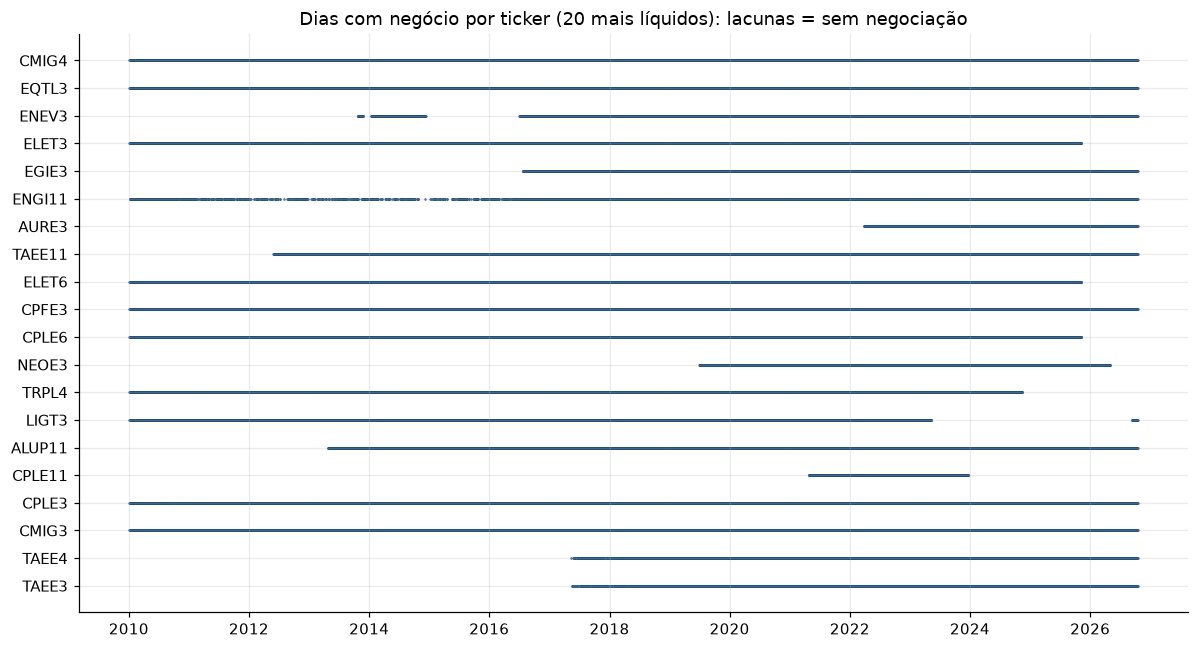

In [8]:
fig, ax = plt.subplots(figsize=(11, 6))
top = cob.index[:20]
for i, tk in enumerate(top[::-1]):
    d = lp[lp.codneg == tk].data_pregao
    ax.scatter(d, np.full(len(d), i), s=0.3, color=AZUL)
ax.set_yticks(range(len(top)), top[::-1]); ax.set_title("Dias com negócio por ticker (20 mais líquidos): lacunas = sem negociação")
plt.tight_layout(); plt.show()

### 4.2 Estatísticas descritivas (lote padrão)

In [9]:
display(lp[["preabe", "premax", "premin", "premed", "preult", "totneg", "quatot", "voltot"]].describe().T)

# retornos diários do preço BRUTO (atenção: incluem desdobramentos e ex-dividendos)
lp = lp.sort_values(["codneg", "data_pregao"])
lp["ret_bruto"] = lp.groupby("codneg").preult.transform(lambda s: np.log(s).diff())
lp["amplitude_%"] = (lp.premax / lp.premin - 1) * 100
est = lp[lp.codneg.isin(cob.index[:12])].groupby("codneg").agg(
    ret_médio_diário_pct=("ret_bruto", lambda r: 100 * r.mean()), vol_anual_pct=("ret_bruto", lambda r: 100 * r.std() * np.sqrt(252)),
    pior_dia_pct=("ret_bruto", lambda r: 100 * r.min()), melhor_dia_pct=("ret_bruto", lambda r: 100 * r.max()),
    amplitude_mediana_pct=("amplitude_%", "median"))
display(est.loc[cob.index[:12]])

,count,mean,std,min,25%,50%,75%,max
preabe,"93,640.00",25.02,16.24,0.53,11.67,22.20,35.36,104.90
premax,"93,640.00",25.33,16.42,0.54,11.80,22.50,35.79,104.93
premin,"93,640.00",24.71,16.08,0.39,11.51,21.91,35.00,103.30
premed,"93,640.00",25.01,16.25,0.49,11.65,22.18,35.35,103.85
preult,"93,640.00",25.04,16.28,0.47,11.67,22.20,35.38,104.41
totneg,"93,640.00","4,535.37","7,046.13",1.00,35.00,"1,518.00","6,253.00","97,355.00"
quatot,"93,640.00","1,730,152.52","3,810,735.08",100.00,"7,600.00","372,050.00","1,647,000.00","154,851,600.00"
voltot,"93,640.00","36,988,913.45","80,161,124.62",165.00,"107,811.25","8,328,720.50","42,345,168.25","4,943,418,554.00"


,ret_médio_diário_pct,vol_anual_pct,pior_dia_pct,melhor_dia_pct,amplitude_mediana_pct
codneg,,,,,
CMIG4,-0.02,40.61,-30.90,16.38,2.71
EQTL3,0.02,49.27,-160.31,12.86,2.38
ENEV3,0.07,113.05,-137.05,323.16,2.96
ELET3,0.01,47.58,-33.33,40.08,3.29
EGIE3,-0.01,26.59,-33.56,9.46,2.00
ENGI11,0.05,34.05,-18.74,14.90,2.23
AURE3,-0.01,28.12,-11.56,11.73,2.39
TAEE11,-0.01,37.95,-111.18,11.96,1.99
ELET6,0.02,43.12,-22.42,27.82,3.18


### 4.3 Por que o preço bruto não serve para calcular retorno

O "pior dia" da tabela acima é quase sempre um **desdobramento ou bonificação**, e não uma queda real. No gráfico, cada degrau vertical da CMIG4 é uma bonificação (2020, 2021, 2022, 2024) e o da EQTL3 em nov/2019 é um desdobramento 1:5.

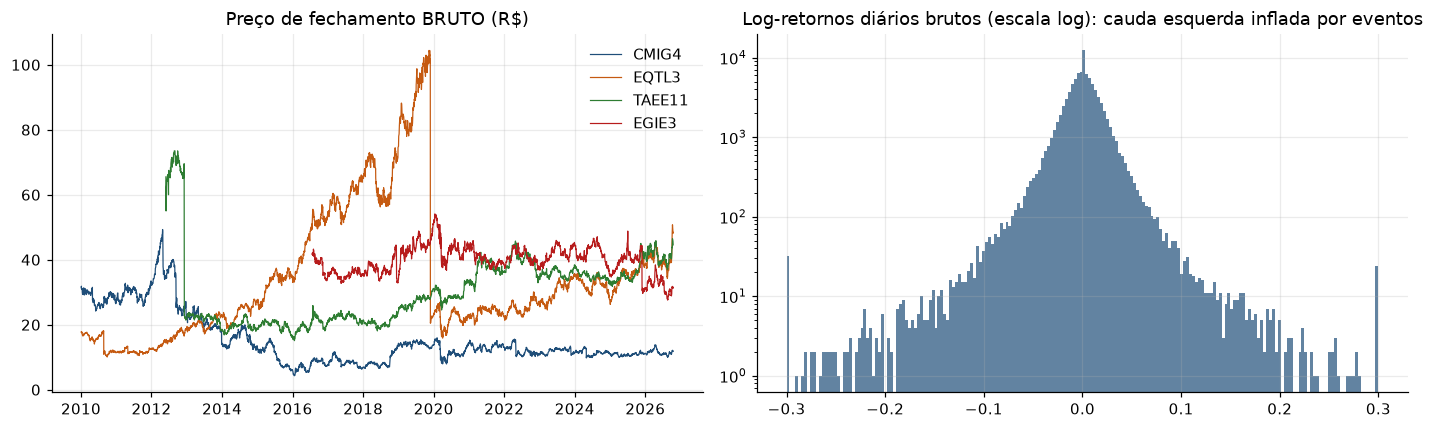

154 dias com |retorno bruto| > 20%; os maiores:


,codneg,data_pregao,ret_bruto
49943,ENEV3,2016-07-01,3.23
35393,CPLE6,2021-03-12,-2.28
30738,CPLE3,2021-03-12,-2.27
32151,CPLE5,2021-06-18,-1.83
67206,EQTL3,2019-11-28,-1.60
32152,CPLE5,2021-06-22,1.39
51103,ENEV3,2021-03-12,-1.37
95440,TRPL4,2019-04-05,-1.36
91754,TRPL3,2019-04-05,-1.31
82646,TAEE11,2012-12-05,-1.11


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for tk, c in [("CMIG4", AZUL), ("EQTL3", LARANJA), ("TAEE11", VERDE), ("EGIE3", VERMELHO)]:
    d = lp[lp.codneg == tk]
    ax[0].plot(d.data_pregao, d.preult, lw=0.8, color=c, label=tk)
ax[0].set_title("Preço de fechamento BRUTO (R$)"); ax[0].legend()
grandes = lp[lp.ret_bruto.abs() > 0.20][["codneg", "data_pregao", "ret_bruto"]]
ax[1].hist(lp.ret_bruto.dropna().clip(-0.3, 0.3), bins=200, color=AZUL, alpha=0.7)
ax[1].set_yscale("log"); ax[1].set_title("Log-retornos diários brutos (escala log): cauda esquerda inflada por eventos")
plt.tight_layout(); plt.show()
print(f"{len(grandes)} dias com |retorno bruto| > 20%; os maiores:")
display(grandes.reindex(grandes.ret_bruto.abs().sort_values(ascending=False).index).head(10))

### 4.4 Liquidez ao longo do tempo

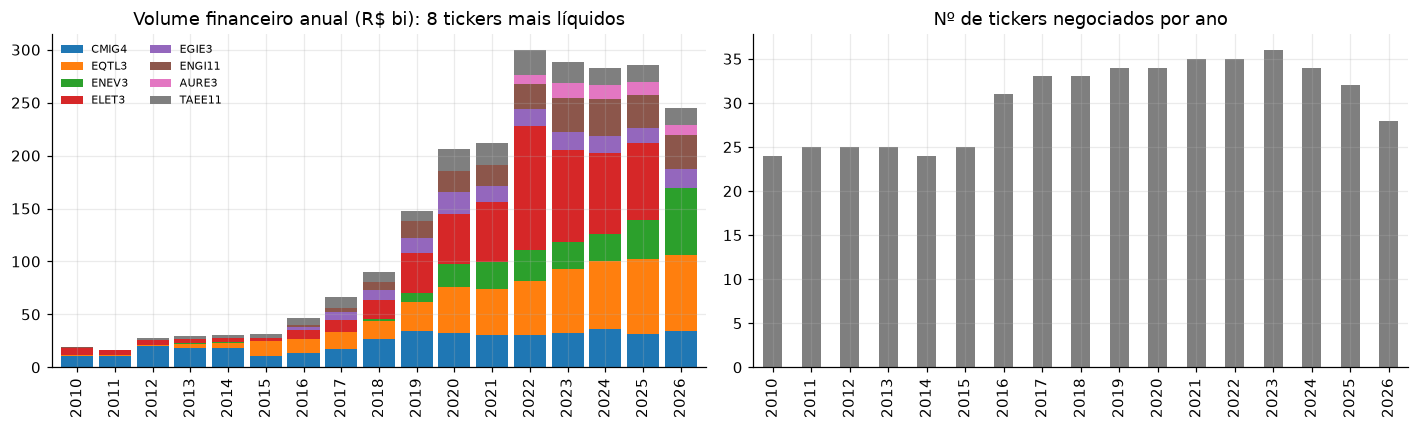

In [11]:
vol_ano = lp.groupby([lp.data_pregao.dt.year, "codneg"]).voltot.sum().unstack().fillna(0) / 1e9
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
vol_ano[cob.index[:8]].plot.bar(stacked=True, ax=ax[0], width=0.85)
ax[0].set_title("Volume financeiro anual (R$ bi): 8 tickers mais líquidos"); ax[0].legend(fontsize=7, ncol=2); ax[0].set_xlabel("")
lp.groupby(lp.data_pregao.dt.year).codneg.nunique().plot.bar(ax=ax[1], color=CINZA)
ax[1].set_title("Nº de tickers negociados por ano"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

---
## 5. Puts

### 5.1 Ligando cada put à sua ação

A put **não** traz o ticker da ação; traz o **ISIN do ativo-objeto** (`codisi`). Ligamos pelo ISIN com a linha de lote padrão da ação no mesmo dia, o que dá o preço da ação ($S$) e permite calcular:

* **moneyness** $K/S$: abaixo de 1 = fora do dinheiro (OTM), acima de 1 = dentro do dinheiro (ITM);
* **dias corridos e dias úteis até o vencimento**;
* **valor intrínseco** $\max(K-S,0)$ e **valor extrínseco** (prêmio − intrínseco).

In [12]:
isin_tk = lp.sort_values("voltot").drop_duplicates("codisi", keep="last").set_index("codisi").codneg  # ISIN → ticker principal
puts["ação"] = puts.codisi.map(isin_tk)
S = lp[["data_pregao", "codneg", "preult"]].rename(columns={"codneg": "ação", "preult": "S"})
puts = puts.merge(S, on=["data_pregao", "ação"], how="left")
puts["chave_serie"] = puts.codneg + "_" + puts.datven.dt.strftime("%Y-%m-%d")
puts["dias_corridos"] = (puts.datven - puts.data_pregao).dt.days
puts["dias_uteis"] = np.busday_count(puts.data_pregao.values.astype("datetime64[D]"), puts.datven.values.astype("datetime64[D]"))
puts["K_S"] = puts.preexe / puts.S
puts["intrinseco"] = (puts.preexe - puts.S).clip(lower=0)
puts["extrinseco"] = puts.preult - puts.intrinseco
print(f"puts ligadas a uma ação: {puts.ação.notna().mean():.2%} | com preço da ação no mesmo dia: {puts.S.notna().mean():.2%}")
print("(dias úteis via np.busday_count: não descontam feriados, então é uma aproximação)")

puts ligadas a uma ação: 99.98% | com preço da ação no mesmo dia: 99.93%
(dias úteis via np.busday_count: não descontam feriados, então é uma aproximação)


### 5.2 Cobertura por ação-objeto

,linhas,séries,primeiro,último,negócios_totais,volume_total_R_mi,negócios_por_linha_mediana,strike_mediano
ação,,,,,,,,
ELET3,56317,3859,2010-02-08,2025-11-07,416004,"1,572.31",3.00,37.53
EQTL3,44553,3769,2010-01-21,2026-10-16,428409,"1,249.34",3.00,32.83
CMIG4,52031,3325,2010-07-20,2026-10-16,617600,892.92,3.00,11.07
ENEV3,17015,1404,2014-02-21,2026-10-16,125463,846.38,2.00,15.00
ELET6,30841,2927,2011-03-18,2025-11-07,277851,534.19,3.00,40.18
EGIE3,46128,2649,2017-02-23,2026-10-16,587242,400.32,3.00,38.85
TAEE11,45300,2460,2014-05-07,2026-10-16,450691,337.47,3.00,35.99
ENGI11,10189,1480,2016-12-06,2026-10-16,34653,286.16,1.00,45.86
CPLE3,4919,329,2024-05-21,2026-10-16,27452,279.90,2.00,14.30


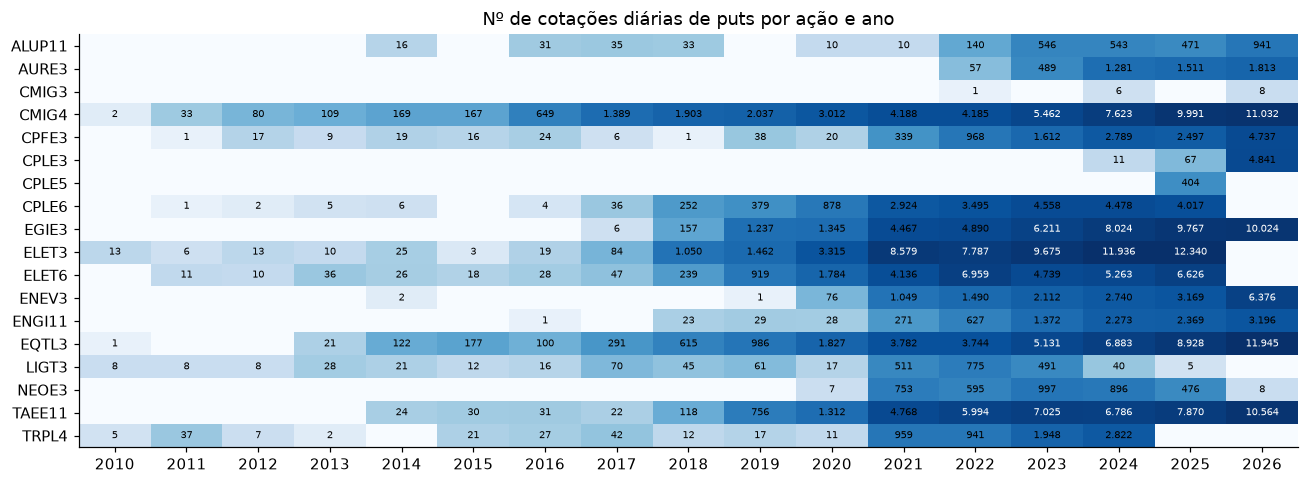

In [13]:
cob_p = puts.groupby("ação").agg(linhas=("codneg", "size"), séries=("chave_serie", "nunique"),
                                 primeiro=("data_pregao", "min"), último=("data_pregao", "max"),
                                 negócios_totais=("totneg", "sum"), volume_total_R_mi=("voltot", lambda v: v.sum() / 1e6),
                                 negócios_por_linha_mediana=("totneg", "median"),
                                 strike_mediano=("preexe", "median")).sort_values("volume_total_R_mi", ascending=False)
display(cob_p)

linhas_ano = puts.groupby([puts.data_pregao.dt.year, "ação"]).size().unstack().fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(12, 4.5))
im = ax.imshow(np.log10(linhas_ano.T.values + 1), aspect="auto", cmap="Blues")
ax.set_xticks(range(len(linhas_ano)), linhas_ano.index); ax.set_yticks(range(len(linhas_ano.columns)), linhas_ano.columns)
for i in range(linhas_ano.shape[1]):
    for j in range(linhas_ano.shape[0]):
        v = linhas_ano.values[j, i]
        if v:
            ax.text(j, i, f"{v:,}".replace(",", "."), ha="center", va="center", fontsize=6.5,
                    color="white" if v > 5000 else "k")
ax.set_title("Nº de cotações diárias de puts por ação e ano"); ax.grid(False)
plt.tight_layout(); plt.show()

### 5.3 Estatísticas descritivas das puts

In [14]:
display(puts[["preult", "preexe", "S", "K_S", "dias_corridos", "dias_uteis", "intrinseco", "extrinseco",
              "totneg", "quatot", "voltot"]].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T)
print(f"linhas com 1 único negócio no dia: {np.mean(puts.totneg == 1):.1%}")
print(f"linhas com prêmio de R$ 0,01 (preço mínimo, 'opção pó'): {np.mean(puts.preult <= 0.01):.1%}")
print(f"linhas com prêmio abaixo do valor intrínseco (extrínseco < -0,05): {np.mean(puts.extrinseco < -0.05):.1%} "
      "(possível na put europeia ITM com juros altos, ou por assincronia com o preço da ação)")

,count,mean,std,min,5%,25%,50%,75%,95%,max
preult,"362,553.00",0.87,1.68,0.01,0.02,0.15,0.45,1.05,2.96,157.95
preexe,"362,553.00",29.88,13.38,1.70,9.06,15.38,33.60,39.49,46.60,210.00
S,"362,287.00",30.79,13.67,1.65,9.64,15.36,34.70,40.53,47.89,104.41
K_S,"362,287.00",0.98,0.11,0.21,0.84,0.93,0.98,1.01,1.11,7.70
dias_corridos,"362,553.00",41.59,54.31,0.00,2.00,16.00,32.00,50.00,95.00,753.00
dias_uteis,"362,553.00",30.14,38.81,0.00,2.00,12.00,23.00,36.00,69.00,539.00
intrinseco,"362,287.00",0.52,1.85,0.00,0.00,0.00,0.00,0.35,2.81,182.73
extrinseco,"362,287.00",0.35,0.53,-31.97,-0.15,0.06,0.22,0.53,1.26,7.62
totneg,"362,553.00",9.03,216.67,1.00,1.00,1.00,3.00,7.00,28.00,"90,096.00"
quatot,"362,553.00","25,258.29","208,917.09",1.00,100.00,500.00,"2,200.00","10,100.00","64,600.00","17,022,100.00"


linhas com 1 único negócio no dia: 31.5%
linhas com prêmio de R$ 0,01 (preço mínimo, 'opção pó'): 2.9%
linhas com prêmio abaixo do valor intrínseco (extrínseco < -0,05): 7.8% (possível na put europeia ITM com juros altos, ou por assincronia com o preço da ação)


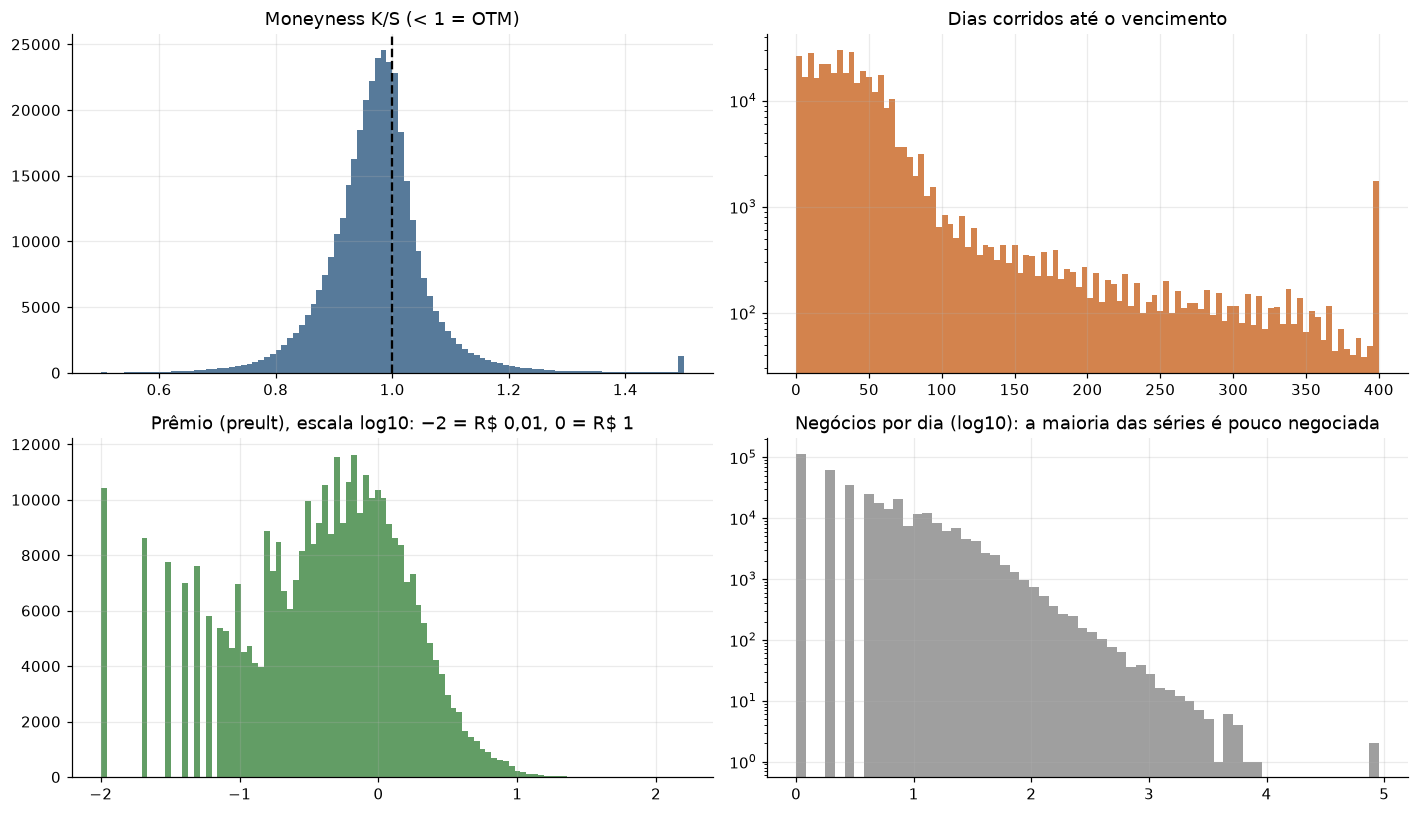

In [15]:
fig, ax = plt.subplots(2, 2, figsize=(13, 7.5))
ax[0, 0].hist(puts.K_S.dropna().clip(0.5, 1.5), bins=100, color=AZUL, alpha=0.75)
ax[0, 0].axvline(1, color="k", ls="--"); ax[0, 0].set_title("Moneyness K/S (< 1 = OTM)")
ax[0, 1].hist(puts.dias_corridos.clip(0, 400), bins=100, color=LARANJA, alpha=0.75)
ax[0, 1].set_title("Dias corridos até o vencimento"); ax[0, 1].set_yscale("log")
ax[1, 0].hist(np.log10(puts.preult), bins=100, color=VERDE, alpha=0.75)
ax[1, 0].set_title("Prêmio (preult), escala log10: −2 = R\\$ 0,01, 0 = R\\$ 1")
ax[1, 1].hist(np.log10(puts.totneg), bins=60, color=CINZA, alpha=0.75)
ax[1, 1].set_title("Negócios por dia (log10): a maioria das séries é pouco negociada"); ax[1, 1].set_yscale("log")
plt.tight_layout(); plt.show()

In [16]:
# onde está a liquidez: volume por faixa de moneyness e de prazo
puts["faixa_K_S"] = pd.cut(puts.K_S, [0, 0.8, 0.9, 0.97, 1.03, 1.1, 1.2, 10],
                           labels=["<0,80", "0,80–0,90", "0,90–0,97", "0,97–1,03 (ATM)", "1,03–1,10", "1,10–1,20", ">1,20"])
puts["faixa_prazo"] = pd.cut(puts.dias_uteis, [-1, 5, 21, 42, 63, 126, 10_000],
                             labels=["≤5 du", "6–21", "22–42", "43–63", "64–126", ">126"])
liq = puts.pivot_table(index="faixa_K_S", columns="faixa_prazo", values="voltot", aggfunc="sum", observed=False) / 1e6
display(liq.style.format("{:,.0f}").background_gradient(cmap="Blues", axis=None)
        .set_caption("Volume financeiro total (R$ milhões) por moneyness × prazo"))

faixa_prazo,≤5 du,6–21,22–42,43–63,64–126,>126
faixa_K_S,,,,,,
"<0,80",2,5,7,6,25,17
"0,80–0,90",6,29,92,72,69,32
"0,90–0,97",26,197,383,223,142,32
"0,97–1,03 (ATM)",165,711,"1,017",322,131,63
"1,03–1,10",202,446,522,146,62,20
"1,10–1,20",145,230,227,55,22,11
">1,20",429,212,147,92,37,123


**O que observar.** A liquidez se concentra nas puts **pouco fora do dinheiro até ATM** e com **menos de 1 mês** até o vencimento. Séries longas e muito fora do dinheiro existem, mas são negociadas raramente: a última cotação delas pode ter dias de atraso em relação ao preço da ação.

### 5.4 Exemplo: a "cadeia" de puts de um dia e a vida de uma série

ELET3 em 2025-10-27: S = R$ 54.35, 108 séries negociadas


,codneg,datven,dias_uteis,preexe,K_S,preult,intrinseco,extrinseco,totneg,voltot
216647,ELETV510W5,2025-10-31,4,51.00,0.94,0.02,0.00,0.02,2,44.00
216730,ELETV520W5,2025-10-31,4,52.00,0.96,0.03,0.00,0.03,1,9.00
216796,ELETV530W5,2025-10-31,4,53.00,0.98,0.13,0.00,0.13,2,166.00
216906,ELETV540W5,2025-10-31,4,54.00,0.99,0.34,0.00,0.34,6,"11,891.00"
216979,ELETV550W5,2025-10-31,4,55.00,1.01,0.63,0.65,-0.02,2,"5,661.00"
217017,ELETV560W5,2025-10-31,4,56.00,1.03,1.61,1.65,-0.04,2,"11,682.00"
223136,ELETW475W1,2025-11-07,9,47.50,0.87,0.01,0.00,0.01,1,1.00
223665,ELETW495W1,2025-11-07,9,49.50,0.91,0.10,0.00,0.10,1,10.00
223931,ELETW510W1,2025-11-07,9,51.00,0.94,0.20,0.00,0.20,2,40.00
224309,ELETW530W1,2025-11-07,9,53.00,0.98,0.48,0.00,0.48,1,960.00


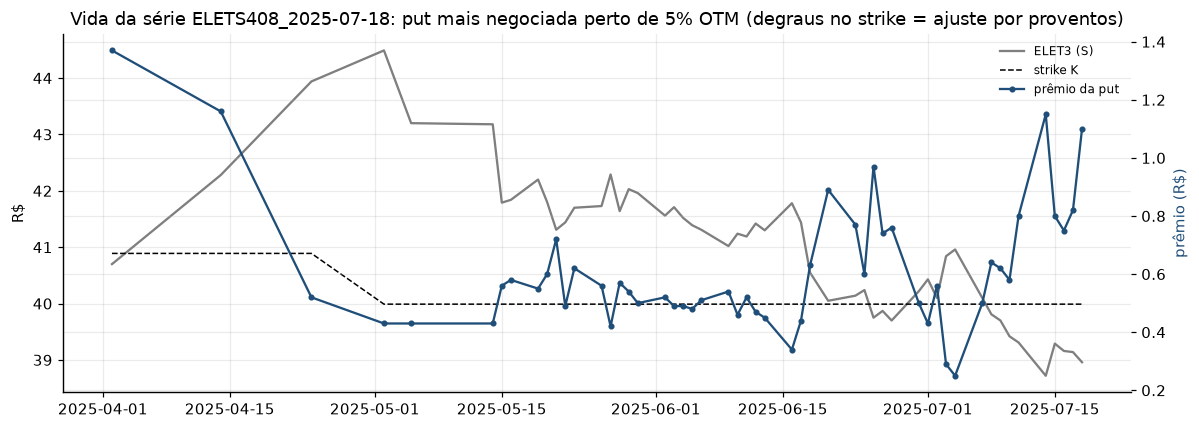

In [17]:
acao_ex = cob_p.index[0]
dia_ex = puts[puts.ação == acao_ex].groupby("data_pregao").size().idxmax()
cadeia = puts[(puts.ação == acao_ex) & (puts.data_pregao == dia_ex)].sort_values(["datven", "preexe"])
print(f"{acao_ex} em {dia_ex.date()}: S = R$ {cadeia.S.iloc[0]:.2f}, {len(cadeia)} séries negociadas")
display(cadeia[["codneg", "datven", "dias_uteis", "preexe", "K_S", "preult", "intrinseco", "extrinseco", "totneg", "voltot"]].head(25))

serie_ex = (puts[(puts.ação == acao_ex) & puts.K_S.between(0.93, 0.97)]
            .groupby("chave_serie").totneg.sum().idxmax())
d = puts[puts.chave_serie == serie_ex].sort_values("data_pregao")
fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.plot(d.data_pregao, d.S, color=CINZA, label=f"{acao_ex} (S)")
ax1.plot(d.data_pregao, d.preexe, color="k", ls="--", lw=1, label="strike K")
ax2 = ax1.twinx()
ax2.plot(d.data_pregao, d.preult, color=AZUL, marker=".", label="prêmio da put")
ax2.set_ylabel("prêmio (R$)", color=AZUL); ax1.set_ylabel("R$")
ax1.set_title(f"Vida da série {serie_ex}: put mais negociada perto de 5% OTM (degraus no strike = ajuste por proventos)")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax1.legend(h1 + h2, l1 + l2, fontsize=8)
plt.tight_layout(); plt.show()

---
## 6. Checagens de qualidade

In [18]:
def checagens(d, nome, chave):
    return pd.Series({
        "linhas": len(d),
        "duplicadas (mesma chave)": int(d.duplicated(chave).sum()),
        "valores nulos": int(d[["preabe", "premax", "premin", "preult", "voltot"]].isna().sum().sum()),
        "premax < premin": int((d.premax < d.premin).sum()),
        "preult fora de [premin, premax]": int(((d.preult > d.premax + 1e-9) | (d.preult < d.premin - 1e-9)).sum()),
        "premed fora de [premin, premax]": int(((d.premed > d.premax + 1e-9) | (d.premed < d.premin - 1e-9)).sum()),
        "preço ≤ 0": int((d[["preabe", "premax", "premin", "preult"]] <= 0).any(axis=1).sum()),
        # a B3 publica premed TRUNCADO no centavo: 0 ≤ voltot/quatot − premed < 0,01
        "premed ≠ voltot/quatot truncado": int((((d.voltot / d.quatot) - d.premed) < -1e-6).sum()
                                               + (((d.voltot / d.quatot) - d.premed) > 0.01 + 1e-6).sum()),
    }, name=nome)
qual = pd.concat([checagens(acoes, "ações", ["data_pregao", "codneg", "codbdi"]),
                  checagens(puts, "puts", ["data_pregao", "codneg", "datven"])], axis=1)
display(qual)
dif = acoes.voltot / acoes.quatot - acoes.premed
fora = acoes[(dif < -1e-6) | (dif > 0.01 + 1e-6)]
print(f"ações fora da regra do truncamento, por ano: {fora.data_pregao.dt.year.value_counts().sort_index().to_dict()}")
print(f"séries de puts que vencem depois do último pregão do arquivo (ainda abertas): "
      f"{puts[puts.datven > puts.data_pregao.max()].chave_serie.nunique()}")
print(f"códigos de put reutilizados em mais de um vencimento: "
      f"{(puts.groupby('codneg').datven.nunique() > 1).sum()} → sempre use (codneg, datven) como chave")
print(f"puts cujo strike mudou durante a vida (ajuste por proventos): "
      f"{(puts.groupby('chave_serie').preexe.nunique() > 1).mean():.1%} das séries")

,ações,puts
linhas,96841,362553
duplicadas (mesma chave),0,0
valores nulos,0,0
premax < premin,0,0
"preult fora de [premin, premax]",1,0
"premed fora de [premin, premax]",55,0
preço ≤ 0,0,0
premed ≠ voltot/quatot truncado,1167,0


ações fora da regra do truncamento, por ano: {2010: 261, 2011: 200, 2012: 209, 2013: 123, 2014: 118, 2015: 112, 2016: 56, 2017: 88}
séries de puts que vencem depois do último pregão do arquivo (ainda abertas): 1027
códigos de put reutilizados em mais de um vencimento: 5633 → sempre use (codneg, datven) como chave
puts cujo strike mudou durante a vida (ajuste por proventos): 25.4% das séries


**Como ler:**
* Zeros são o esperado. Os poucos casos de ações com `premed` ou `preult` fora de [mínima, máxima] são de 1 a 10 centavos, em papéis pouco líquidos (ALUP3/4, COCE3/5). Para análises, use `preult`.
* `premed` é o preço médio **truncado** no centavo: `voltot / quatot` é o médio exato. Nas puts a regra vale em 100% das linhas. Nas ações, as exceções aparecem só em 2010–2017 e são de poucos centavos (provável mudança de metodologia da B3); desde 2018 a regra vale sempre. Em puts de R$ 0,10, esse truncamento chega a 10%. **Para o preço médio de opções baratas, calcule `voltot / quatot`** em vez de usar `premed`.
* O ajuste de strike por proventos é normal na B3 e explica por que uma mesma série aparece com mais de um `preexe`.

---
## 7. Funções de consulta rápida

Para tirar dúvidas sem reescrever filtros:

* `cotacao("CMIG4", "2024-01-01", "2024-03-31")`: OHLC, negócios e volume da ação (lote padrão);
* `cadeia_puts("CMIG4", "2025-03-10")`: todas as puts negociadas naquele dia, com $S$, $K/S$ e prazo;
* `serie_put("CMIGO115")`: histórico de uma série (se o código foi reutilizado, mostra todos os vencimentos);
* `resumo_ticker("TAEE11")`: um painel rápido.

,preabe,premax,premin,preult,totneg,quatot,voltot
data_pregao,,,,,,,
2026-10-09,12.14,12.27,12.10,12.13,21335,22810700,"277,401,997.00"
2026-10-13,12.04,12.04,11.82,11.90,25245,20250600,"241,692,584.00"
2026-10-14,11.85,11.93,11.73,11.90,20565,17245800,"204,372,186.00"
2026-10-15,11.80,11.87,11.66,11.76,17187,17012400,"200,254,743.00"
2026-10-16,11.80,11.88,11.71,11.83,13678,13723500,"161,854,011.00"


,codneg,datven,dias_uteis,preexe,S,K_S,preult,premin,premax,totneg,voltot
347072,TAEEV406W2,2026-10-09,4,40.60,43.89,0.93,0.03,0.02,0.04,5,76.00
347320,TAEEV416W2,2026-10-09,4,41.60,43.89,0.95,0.05,0.03,0.06,5,124.00
347446,TAEEV421W2,2026-10-09,4,42.10,43.89,0.96,0.04,0.04,0.08,3,89.00
347494,TAEEV426W2,2026-10-09,4,42.60,43.89,0.97,0.10,0.07,0.10,3,25.00
347656,TAEEV436W2,2026-10-09,4,43.60,43.89,0.99,0.21,0.18,0.22,20,"16,764.00"
344862,TAEEV353,2026-10-16,9,34.85,43.89,0.79,0.01,0.01,0.01,1,8.00
345788,TAEEV370,2026-10-16,9,35.10,43.89,0.80,0.01,0.01,0.01,1,5.00
345099,TAEEV358,2026-10-16,9,35.35,43.89,0.81,0.01,0.01,0.01,2,6.00
345423,TAEEV363,2026-10-16,9,35.85,43.89,0.82,0.01,0.01,0.01,2,2.00
346246,TAEEV380,2026-10-16,9,36.10,43.89,0.82,0.02,0.02,0.02,1,2.00


,data_pregao,datven,preexe,S,K_S,preult,totneg,voltot
17021,2018-11-16,2019-03-18,11.50,11.77,0.98,0.90,2,"3,150.00"
17022,2019-02-13,2019-03-18,11.38,13.50,0.84,0.09,2,"2,200.00"
17023,2019-03-13,2019-03-18,11.38,14.70,0.77,0.02,1,70.00
17024,2023-01-09,2023-03-17,11.32,11.16,1.01,0.61,11,"1,399.00"
17025,2023-01-10,2023-03-17,11.32,11.22,1.01,0.64,3,383.00
...,...,...,...,...,...,...,...,...
17161,2026-09-28,2027-03-19,11.30,10.84,1.04,0.65,2,265.00
17162,2026-10-05,2027-03-19,11.30,11.98,0.94,0.23,3,160.00
17163,2026-10-09,2027-03-19,11.30,12.13,0.93,0.25,2,150.00
17164,2026-10-13,2027-03-19,11.30,11.90,0.95,0.30,2,150.00


TAEE11 (TAESA, UNT     N2): 2012-05-29 a 2026-10-16, 3564 pregões, último preço bruto R$ 44.56
  puts: 45300 cotações, 2460 séries, de 2014-05-07 a 2026-10-16


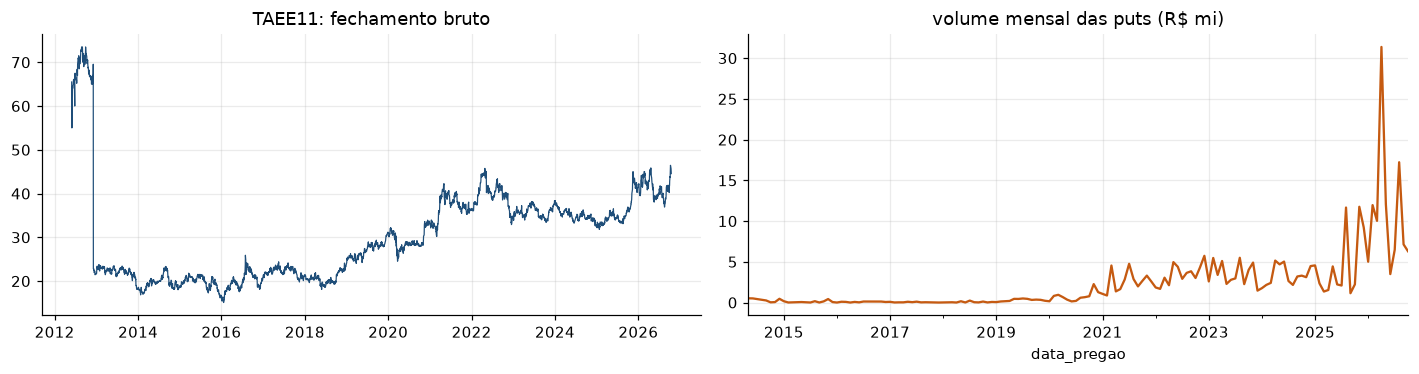

In [19]:
def cotacao(ticker, inicio=None, fim=None):
    d = lp[lp.codneg == ticker].set_index("data_pregao")
    return d.loc[inicio:fim, ["preabe", "premax", "premin", "preult", "totneg", "quatot", "voltot"]]

def cadeia_puts(acao, data, max_dias_uteis=None):
    d = puts[(puts.ação == acao) & (puts.data_pregao == pd.Timestamp(data))]
    if max_dias_uteis is not None:
        d = d[d.dias_uteis <= max_dias_uteis]
    return d.sort_values(["datven", "preexe"])[["codneg", "datven", "dias_uteis", "preexe", "S", "K_S", "preult", "premin", "premax", "totneg", "voltot"]]

def serie_put(codneg, datven=None):
    d = puts[puts.codneg == codneg]
    if datven is not None:
        d = d[d.datven == pd.Timestamp(datven)]
    return d.sort_values("data_pregao")[["data_pregao", "datven", "preexe", "S", "K_S", "preult", "totneg", "voltot"]]

def resumo_ticker(ticker):
    d = lp[lp.codneg == ticker]
    p = puts[puts.ação == ticker]
    print(f"{ticker} ({d.nomres.iloc[-1]}, {d.especi.iloc[-1]}): {d.data_pregao.min().date()} a {d.data_pregao.max().date()}, "
          f"{len(d)} pregões, último preço bruto R$ {d.preult.iloc[-1]:.2f}")
    print(f"  puts: {len(p)} cotações, {p.chave_serie.nunique()} séries"
          + (f", de {p.data_pregao.min().date()} a {p.data_pregao.max().date()}" if len(p) else " (nenhuma)"))
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
    ax[0].plot(d.data_pregao, d.preult, color=AZUL, lw=0.8); ax[0].set_title(f"{ticker}: fechamento bruto")
    if len(p):
        p.groupby(p.data_pregao.dt.to_period("M")).voltot.sum().div(1e6).plot(ax=ax[1], color=LARANJA)
        ax[1].set_title("volume mensal das puts (R$ mi)")
    plt.tight_layout(); plt.show()

display(cotacao("CMIG4", "2026-10-01").tail())
dia_taee = puts[puts.ação == "TAEE11"].groupby("data_pregao").size().idxmax()   # dia com mais séries negociadas
display(cadeia_puts("TAEE11", dia_taee, max_dias_uteis=30).head(10))
display(serie_put("CMIGO115"))
resumo_ticker("TAEE11")